#### Recover a randomized mean difference

In [15]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

In [16]:
# Fix the seed so rerunning the cell gives the same example.
rng = np.random.default_rng(4)
n = 1200
# Random assignment with full compliance: 1 = uses Coach, 0 = does not.
used_coach = rng.binomial(1, 0.5, n)
# Coach adds 2.4 orders; random noise creates variation across sellers.
# This is a simplified continuous outcome, not a model of integer counts.
orders_30d = 18 + 2.4 * used_coach + rng.normal(0, 5, n)

sellers = pd.DataFrame({
    "used_coach": used_coach,
    "orders_30d": orders_30d,
})

# Calculate the group averages directly.
means = sellers.groupby("used_coach")["orders_30d"].mean()
# With a binary treatment and an intercept, OLS gives the same difference.
model = smf.ols("orders_30d ~ used_coach", data=sellers).fit()

pd.DataFrame({
    "Quantity": ["Difference in means", "Treatment coefficient"],
    "Additional orders": [means.loc[1] - means.loc[0], model.params["used_coach"]],
}).round(3)

,Quantity,Additional orders
0,Difference in means,2.496
1,Treatment coefficient,2.496


#### Adjust when sellers choose for themselves, not random assignment any more

##### confounders: used_coach + pre_orders + tenure_months

In [18]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# Create seller histories before anyone uses Coach.
rng = np.random.default_rng(12)
n = 3000
tenure_months = rng.exponential(18, n)
pre_orders = rng.poisson(8 + tenure_months / 8)
# Higher prior orders now make adoption more likely: usage is not randomized.
use_probability = 1 / (1 + np.exp(-(-2.2 + 0.12 * pre_orders)))
used_coach = rng.binomial(1, use_probability)

# Both seller history and Coach affect future orders.
true_effect = 2.4
orders_30d = (
    5 + 0.60 * pre_orders + 0.04 * tenure_months
    + true_effect * used_coach + rng.normal(0, 4, n)
)

sellers = pd.DataFrame({
    "orders_30d": orders_30d,
    "used_coach": used_coach,
    "pre_orders": pre_orders,
    "tenure_months": tenure_months,
})

# First compare users and nonusers without accounting for their histories.
short = smf.ols("orders_30d ~ used_coach", data=sellers).fit()
# Then account for prior orders and tenure.
# HC3 changes the standard errors, not the fitted coefficients.
long = smf.ols(
    "orders_30d ~ used_coach + pre_orders + tenure_months",
    data=sellers,
).fit(cov_type="HC3")

pd.DataFrame({
    "Estimate": ["Unadjusted coefficient", "Adjusted coefficient", "True effect"],
    "Additional orders": [short.params["used_coach"], long.params["used_coach"], true_effect],
}).round(3)

,Estimate,Additional orders
0,Unadjusted coefficient,4.136
1,Adjusted coefficient,2.617
2,True effect,2.400


#### What adjustment removes? --> Residualization. 

##### First, predict usage from prior orders and tenure with a linear regression. Subtract that prediction from actual usage. What remains is the residual: the part this model did not explain.

##### Then relate that remaining variation in usage to future orders.

In [19]:
# Recreate the previous sample so we compare calculations on identical data.
rng = np.random.default_rng(12)
n = 3000
tenure = rng.exponential(18, n)
pre_orders = rng.poisson(8 + tenure / 8)
used_coach = rng.binomial(
    1,
    1 / (1 + np.exp(-(-2.2 + 0.12 * pre_orders))),
)
orders_30d = (
    5 + 0.60 * pre_orders + 0.04 * tenure
    + 2.4 * used_coach + rng.normal(0, 4, n)
)

sellers = pd.DataFrame({
    "orders_30d": orders_30d,
    "used_coach": used_coach,
    "pre_orders": pre_orders,
    "tenure": tenure,
})

# Use linear regression here: this identity relies on a linear projection.
t_model = smf.ols("used_coach ~ pre_orders + tenure", data=sellers).fit()
# Residual = actual usage minus the usage predicted by these controls.
t_residual = t_model.resid
# Regress orders on the usage residual; dot products calculate the slope.
residualized_effect = np.dot(t_residual, orders_30d) / np.dot(t_residual, t_residual)

# Compare that slope with the treatment coefficient from the full model.
full_model = smf.ols(
    "orders_30d ~ used_coach + pre_orders + tenure",
    data=sellers,
).fit()

pd.DataFrame({
    "Calculation": ["Residualized treatment", "Full regression"],
    "Treatment effect": [residualized_effect, full_model.params["used_coach"]],
}).round(4)

,Calculation,Treatment effect
0,Residualized treatment,2.6168
1,Full regression,2.6168


#### Estimate the effect for the population we care about

##### Standardization: predict each seller's orders with and without listing coach, then average the difference. 
##### ATE: averages over all eligible sellers.
##### ATT: averages over current users. 

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

,Estimate,Additional orders
0,Naive gap,4.50
1,Standardized ATE,2.59
2,Standardized ATT,2.63
3,True ATE,2.31


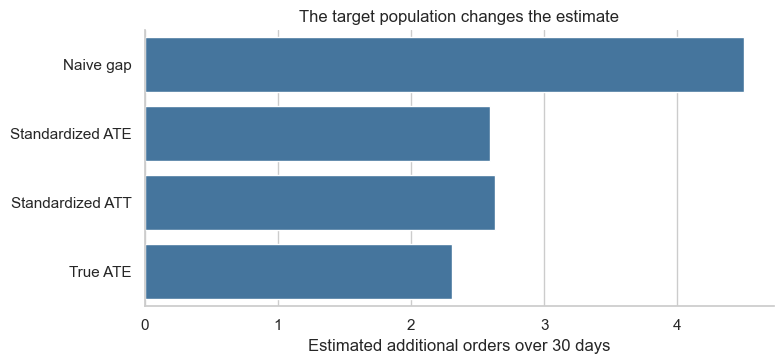

In [24]:
# Use a new sample where the effect can differ across sellers.
rng = np.random.default_rng(23)
n = 4000
tenure = rng.exponential(18, n)
pre_orders = rng.poisson(8 + tenure / 8)
category = rng.choice(["Home", "Beauty", "Electronics"], n)
# Adoption depends on activity and experience, so selection is still present.
used_coach = rng.binomial(
    1,
    1 / (1 + np.exp(-(-2.2 + 0.11 * pre_orders + 0.018 * tenure))),
)

# More active sellers benefit more. Keep this truth only for validation.
true_effect = 1.6 + 0.07 * pre_orders
orders_30d = (
    5 + 0.55 * pre_orders + 0.04 * tenure
    + 1.2 * (category == "Electronics")
    + true_effect * used_coach + rng.normal(0, 4, n)
)

sellers = pd.DataFrame({
    "orders_30d": orders_30d,
    "used_coach": used_coach,
    "pre_orders": pre_orders,
    "tenure": tenure,
    "category": category,
    "true_effect": true_effect,
})

# The interaction (*) lets Coach's effect vary with prior orders.
# I(...) adds a curve; C(...) treats category as categorical.
# Do not include true_effect: it would be unknown in real data.
model = smf.ols(
    "orders_30d ~ used_coach * pre_orders + I(pre_orders ** 2) + tenure + C(category)",
    data=sellers,
).fit(cov_type="HC3")

# Predict twice for each seller, keeping all other characteristics unchanged.
# These are model predictions, not two observed outcomes for each person.
effect_hat = (
    model.predict(sellers.assign(used_coach=1))
    - model.predict(sellers.assign(used_coach=0))
)

naive = sellers.groupby("used_coach")["orders_30d"].mean().diff().iloc[-1]
# ATE averages all sellers; ATT averages only those who actually used Coach.
comparison = pd.DataFrame({
    "Estimate": ["Naive gap", "Standardized ATE", "Standardized ATT", "True ATE"],
    "Additional orders": [
        naive,
        effect_hat.mean(),
        effect_hat[sellers["used_coach"] == 1].mean(),
        true_effect.mean(),
    ],
}).round(2)

# Plot the computed estimates, then return the same values as a table.
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=comparison, x="Additional orders", y="Estimate", color="#3776AB", ax=ax)
ax.set_title("The target population changes the estimate")
ax.set_xlabel("Estimated additional orders over 30 days")
ax.set_ylabel("")
sns.despine()
fig.tight_layout()

comparison

##### $aw difference of 4.50 orders, an estimated ATE of 2.59, and an estimated ATT of 2.63. These are additional orders per seller over 30 days. Adjustment brings the estimate down substantially from the raw comparison.

##### ATT is about 0.04 orders higher than ATE because current users tend to be more active, and we made Coach more helpful for active sellers. The same fitted model produces both estimates; only the sellers we average over change.

##### The true ATE is 2.31 orders, so our estimated ATE is about 0.28 orders too high in this sample. Knowing the truth lets us see the estimation error here. With real data, we would need confidence intervals and assumption checks, not just these point estimates.

##### ATT estimates the benefit for current users. ATE estimates the average benefit if every eligible seller used the feature. Neither directly tells us the effect of simply offering it: a rollout also depends on who actually adopts.